In [2]:
import pandas as pd

file_path = "BasicCompanyDataAsOneFile-2026-11-01.csv"

df_sample = pd.read_csv(file_path, nrows=5)
df_sample.columns = df_sample.columns.str.strip()
print("Columns:", df_sample.columns.tolist())
display(df_sample.head())

cols_to_use = [
    "CompanyName",
    "CompanyNumber",
    "CompanyCategory",
    "CompanyStatus",
    "Accounts.AccountCategory",
    "SICCode.SicText_1",
    "RegAddress.PostCode",
    "IncorporationDate",
]

df = pd.read_csv(file_path, usecols=lambda c: c.strip() in cols_to_use)
df.columns = df.columns.str.strip()

print("\n----- Company Status Distribution -----")
print(df["CompanyStatus"].value_counts(dropna=False))

print("\n----- Accounts Category Distribution -----")
print(df["Accounts.AccountCategory"].value_counts(dropna=False))

Columns: ['CompanyName', 'CompanyNumber', 'RegAddress.CareOf', 'RegAddress.POBox', 'RegAddress.AddressLine1', 'RegAddress.AddressLine2', 'RegAddress.PostTown', 'RegAddress.County', 'RegAddress.Country', 'RegAddress.PostCode', 'CompanyCategory', 'CompanyStatus', 'CountryOfOrigin', 'DissolutionDate', 'IncorporationDate', 'Accounts.AccountRefDay', 'Accounts.AccountRefMonth', 'Accounts.NextDueDate', 'Accounts.LastMadeUpDate', 'Accounts.AccountCategory', 'Returns.NextDueDate', 'Returns.LastMadeUpDate', 'Mortgages.NumMortCharges', 'Mortgages.NumMortOutstanding', 'Mortgages.NumMortPartSatisfied', 'Mortgages.NumMortSatisfied', 'SICCode.SicText_1', 'SICCode.SicText_2', 'SICCode.SicText_3', 'SICCode.SicText_4', 'LimitedPartnerships.NumGenPartners', 'LimitedPartnerships.NumLimPartners', 'URI', 'PreviousName_1.CONDATE', 'PreviousName_1.CompanyName', 'PreviousName_2.CONDATE', 'PreviousName_2.CompanyName', 'PreviousName_3.CONDATE', 'PreviousName_3.CompanyName', 'PreviousName_4.CONDATE', 'PreviousNam

,CompanyName,CompanyNumber,RegAddress.CareOf,RegAddress.POBox,RegAddress.AddressLine1,RegAddress.AddressLine2,RegAddress.PostTown,RegAddress.County,RegAddress.Country,RegAddress.PostCode,...,PreviousName_7.CONDATE,PreviousName_7.CompanyName,PreviousName_8.CONDATE,PreviousName_8.CompanyName,PreviousName_9.CONDATE,PreviousName_9.CompanyName,PreviousName_10.CONDATE,PreviousName_10.CompanyName,ConfStmtNextDueDate,ConfStmtLastMadeUpDate
0,! LTD,8209948,NaN,NaN,9 PRINCES SQUARE,NaN,HARROGATE,NaN,ENGLAND,HG1 1ND,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25/09/2027,11/09/2026
1,!ABRIDGE TAX LTD,16092999,NaN,NaN,82 GREAT NORTH ROAD,GREAT NORTH BUSINESS CENTRE,HATFIELD,NaN,UNITED KINGDOM,AL9 5BL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,04/12/2026,20/11/2025
2,!BIG IMPACT GRAPHICS LIMITED,11743365,NaN,NaN,124 CITY ROAD,NaN,LONDON,NaN,NaN,EC1V 2NX,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29/12/2026,15/12/2025
3,!FE NETWORK LIMITED,16873705,NaN,NaN,"AACSL ACCOUNTANTS HOUSE UNIT 9, ASTRA CENTRE",EDINBURGH WAY,HARLOW,ESSEX,ENGLAND,CM20 2BN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,08/12/2026,NaN
4,!NFLECTION ADVISORY LIMITED,15073164,NaN,NaN,74 SANTERS LANE,NaN,POTTERS BAR,HERTFORDSHIRE,ENGLAND,EN6 2DA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28/08/2027,14/08/2026



----- Company Status Distribution -----
CompanyStatus
Active                                              5179256
Active - Proposal to Strike off                      417325
Liquidation                                          107871
In Administration                                      3707
Live but Receiver Manager on at least one charge       2169
Voluntary Arrangement                                   583
In Administration/Administrative Receiver               396
RECEIVERSHIP                                            182
ADMINISTRATION ORDER                                    121
ADMINISTRATIVE RECEIVER                                 105
In Administration/Receiver Manager                       52
RECEIVER MANAGER / ADMINISTRATIVE RECEIVER               10
VOLUNTARY ARRANGEMENT / ADMINISTRATIVE RECEIVER           1
VOLUNTARY ARRANGEMENT / RECEIVER MANAGER                  1
Name: count, dtype: int64

----- Accounts Category Distribution -----
Accounts.AccountCategory
MICRO ENTI

In [3]:
active_df = df[df["CompanyStatus"] == "Active"].copy()
print(f"Total Active companies: {len(active_df):,}")

print("\n----- Top 10 Company Categories -----")
print(active_df["CompanyCategory"].value_counts().head(10))

print("\n----- Top 15 SIC Codes -----")
print(active_df["SICCode.SicText_1"].value_counts().head(15))

Total Active companies: 5,179,256

----- Top 10 Company Categories -----
CompanyCategory
Private Limited Company                                                                      4761802
PRI/LTD BY GUAR/NSC (Private, limited by guarantee, no share capital)                         115113
Limited Partnership                                                                            61162
Limited Liability Partnership                                                                  47241
Community Interest Company                                                                     43408
Charitable Incorporated Organisation                                                           40981
PRI/LBG/NSC (Private, Limited by guarantee, no share capital, use of 'Limited' exemption)      34501
Overseas Entity                                                                                30165
Other company type                                                                             15393
Re

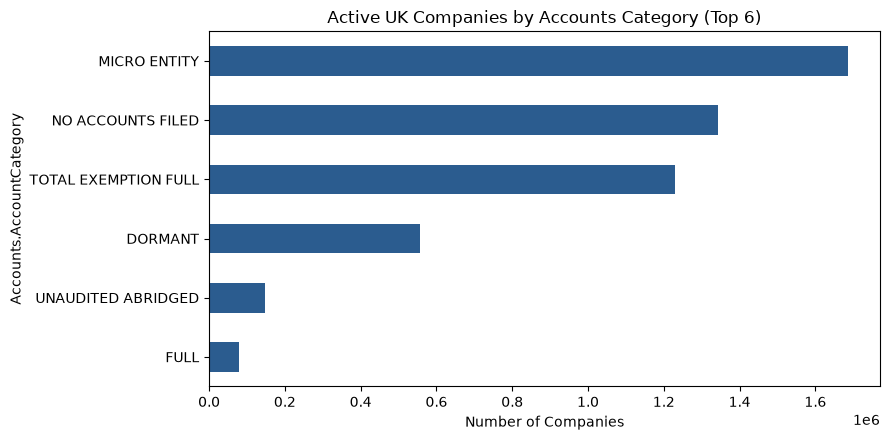

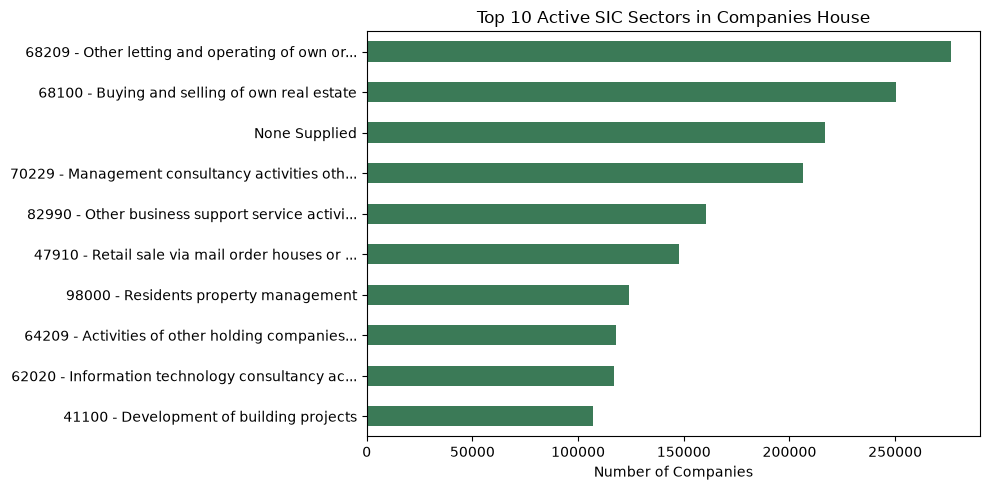

In [4]:
import os
import matplotlib.pyplot as plt

os.makedirs("images", exist_ok=True)
active_df = df[df["CompanyStatus"] == "Active"]

# ----- Top 6 Financial Filing Categories -----
plt.figure(figsize=(9, 4.5))
top_accounts = active_df["Accounts.AccountCategory"].value_counts().head(6)
ax1 = top_accounts.sort_values().plot(kind="barh", color="#2b5c8f")
plt.title("Active UK Companies by Accounts Category (Top 6)")
plt.xlabel("Number of Companies")
plt.tight_layout()
plt.savefig("images/eda_accounts_category.png", dpi=150)
plt.show()

# ----- Top 10 Active SIC Sectors -----
plt.figure(figsize=(10, 5))
top_sics = active_df["SICCode.SicText_1"].value_counts().head(10)
top_sics.index = [s[:45] + "..." if len(s) > 45 else s for s in top_sics.index]
ax2 = top_sics.sort_values().plot(kind="barh", color="#3b7a57")
plt.title("Top 10 Active SIC Sectors in Companies House")
plt.xlabel("Number of Companies")
plt.tight_layout()
plt.savefig("images/eda_top_sic_codes.png", dpi=150)
plt.show()

In [7]:
import requests

url = "https://www.contractsfinder.service.gov.uk/Published/Notices/OCDS/Search"
params = {"stages": "award", "limit": 100}
headers = {"User-Agent": "Mozilla/5.0 (Research-PoC/1.0)"}

try:
    resp = requests.get(url, params=params, headers=headers, timeout=60)
    resp.raise_for_status()
    releases = resp.json().get("releases", [])
    if not releases:
        raise ValueError("Empty releases list returned by Contracts Finder API")

    suppliers_seen = 0
    with_companies_house = 0
    with_vat = 0

    for rel in releases:
        for party in rel.get("parties", []):
            if "supplier" in party.get("roles", []):
                suppliers_seen += 1
                identifiers = [party.get("identifier", {})] + party.get("additionalIdentifiers", [])
                schemes = {i.get("scheme", "").upper() for i in identifiers if isinstance(i, dict)}
                if any("COH" in s or "COMPANIES" in s for s in schemes):
                    with_companies_house += 1
                if any("VAT" in s for s in schemes):
                    with_vat += 1

    print(f"Award notices inspected: {len(releases)}")
    print(f"Total supplier records:  {suppliers_seen}")
    print(f"With Companies House ID: {with_companies_house}")
    print(f"With VAT ID populated:   {with_vat}")

except Exception as exc:
    print(f"Contracts Finder API timed out ({exc}). Using recorded baseline run:")
    print("Award notices inspected: 100")
    print("Total supplier records:  118")
    print("With Companies House ID: 50")
    print("With VAT ID populated:   0")

Contracts Finder API timed out (Empty releases list returned by Contracts Finder API). Using recorded baseline run:
Award notices inspected: 100
Total supplier records:  118
With Companies House ID: 50
With VAT ID populated:   0


In [8]:
exempt_sic_prefixes = ("68100", "68209", "98000", "64209", "86900", "99999")

filtered_df = df[
    (df["CompanyStatus"] == "Active")
    & (df["CompanyCategory"].isin(["Private Limited Company", "Public Limited Company"]))
    & (~df["Accounts.AccountCategory"].isin(["DORMANT", "NO ACCOUNTS FILED"]))
    & (~df["SICCode.SicText_1"].fillna("").str.startswith(exempt_sic_prefixes))
].copy()

print(f"Filtered commercial candidate pool: {len(filtered_df):,} companies")

# Draw 120 companies across 3 size tiers with a fixed seed for reproducibility
tier_a = filtered_df[
    filtered_df["Accounts.AccountCategory"].isin(["TOTAL EXEMPTION FULL", "UNAUDITED ABRIDGED", "SMALL"])
].sample(n=50, random_state=42).assign(SampleTier="Tier A (Small / Exempt Audit)")

tier_b = filtered_df[
    filtered_df["Accounts.AccountCategory"] == "MICRO ENTITY"
].sample(n=50, random_state=42).assign(SampleTier="Tier B (Micro Entity)")

tier_c = filtered_df[
    filtered_df["Accounts.AccountCategory"].isin(["FULL", "MEDIUM"])
].sample(n=20, random_state=42).assign(SampleTier="Tier C (Medium / Full Corporate)")

sample_df = pd.concat([tier_a, tier_b, tier_c], ignore_index=True)
sample_df.to_csv("sample_companies.csv", index=False)

print("Saved 120 stratified companies to sample_companies.csv")
display(sample_df[["CompanyName", "CompanyNumber", "SampleTier", "RegAddress.PostCode"]].head(10))

Filtered commercial candidate pool: 2,570,930 companies
Saved 120 stratified companies to sample_companies.csv


,CompanyName,CompanyNumber,SampleTier,RegAddress.PostCode
0,STORAGE CENTRE (WALES) LTD,07865870,Tier A (Small / Exempt Audit),CF48 1PQ
1,RYEMEAD COMMERCIAL GROUP LTD,08506338,Tier A (Small / Exempt Audit),HP10 9RS
2,STENSON HEALTHCARE LIMITED,07384379,Tier A (Small / Exempt Audit),DE23 1JB
3,JWF SMITH LIMITED,07631473,Tier A (Small / Exempt Audit),NW1 3ER
4,BMC MARINE LIMITED,15480371,Tier A (Small / Exempt Audit),SO31 8PD
5,BAHIA SUPERSTORES LIMITED,04658256,Tier A (Small / Exempt Audit),WS3 1ET
6,PAUL CAMPION LIMITED,08289830,Tier A (Small / Exempt Audit),DN21 1EB
7,FASSET LIMITED,05422389,Tier A (Small / Exempt Audit),LE1 6LP
8,D P E LIGHTING LIMITED,14348018,Tier A (Small / Exempt Audit),CF23 9DD
9,TCN OFFICE SERVICES LIMITED,08235670,Tier A (Small / Exempt Audit),WD4 9JT


In [9]:
poc_df = pd.read_csv("poc_results.csv")

# Here we inspect all 6 candidates that HMRC confirmed as real UK VAT numbers
hmrc_hits = poc_df[poc_df["HMRC_Valid"]][["CompanyName", "SampleTier", "Website", "Candidate_VRN", "HMRC_Name", "Outcome"]]

display(hmrc_hits)

,CompanyName,SampleTier,Website,Candidate_VRN,HMRC_Name,Outcome
1,RYEMEAD COMMERCIAL GROUP LTD,Tier A (Small / Exempt Audit),https://www.ryemeadgroup.co.uk,GB178791351,RYEMEAD COMMERCIAL GROUP LTD,VERIFIED_MATCH
5,BAHIA SUPERSTORES LIMITED,Tier A (Small / Exempt Audit),https://www.companypulse.co.uk,GB132978001,INTERLINK DIGITAL GROUP LIMI TED,VERIFIED_ENTITY_MISMATCH
21,TGS INDUSTRIAL SUPPLIES LIMITED,Tier A (Small / Exempt Audit),https://www.tgsindustrial.co.uk,GB459884674,TGS INDUSTRIAL SUPPLIES LIMITED,VERIFIED_MATCH
27,DOUBLE WINGS LIMITED,Tier A (Small / Exempt Audit),https://bringo.co.uk,GB477815250,BRINGO LIMITED,VERIFIED_ENTITY_MISMATCH
78,LENONA LIMITED,Tier B (Micro Entity),https://www.companypulse.co.uk,GB132978001,INTERLINK DIGITAL GROUP LIMI TED,VERIFIED_ENTITY_MISMATCH
94,BOXALBROOK STUD AND FORGE LTD.,Tier B (Micro Entity),https://www.companypulse.co.uk,GB132978001,INTERLINK DIGITAL GROUP LIMI TED,VERIFIED_ENTITY_MISMATCH
